<a href="https://colab.research.google.com/github/mayamai-a10/data-science-toolkit/blob/main/Tutorial3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


1. Find some real dataset. Load it on Colab, Kaggle etc. Try to visualize some of it

In [3]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/train.csv')

# Display the first five rows
display(df.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


The Titanic dataset was loaded into Google Colab using Pandas. I displayed the first five rows to see what the data looks like.

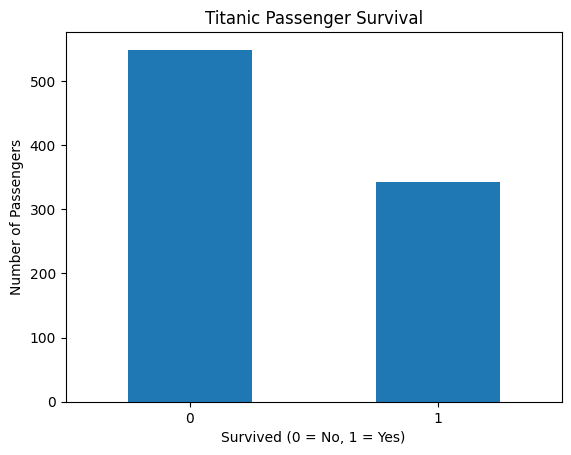

In [5]:
import matplotlib.pyplot as plt

# Count and visualize passenger survival
df['Survived'].value_counts().sort_index().plot(kind='bar')

# Add graph labels
plt.title('Titanic Passenger Survival')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')
plt.xticks(rotation=0)

# Display the graph
plt.show()


Then, I used Matplotlib to create a bar chart showing how many passengers survived and how many did not. This graph helps me understand the survival information in the dataset.

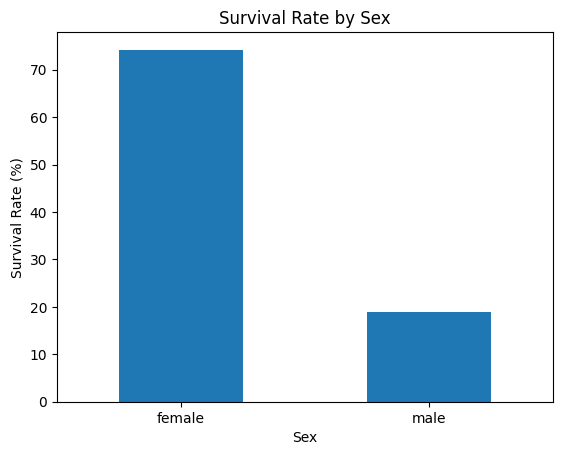

In [6]:
import matplotlib.pyplot as plt

# Calculate the survival rate by sex
survival_rate = df.groupby('Sex')['Survived'].mean() * 100

# Create the bar chart
survival_rate.plot(kind='bar')

# Add title and labels
plt.title('Survival Rate by Sex')
plt.xlabel('Sex')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=0)

# Display the graph
plt.show()

The bar chart shows the survival rate of male and female passengers on the Titanic. From the graph, we can compare the percentage of passengers who survived in each group. The survival rate for female passengers was higher than that for male passengers, suggesting that sex was associated with survival in this dataset.

2. Evaluate if the data is good or not. Does it have enough samples?

In [9]:
print("Rows and columns:", df.shape)
print("Repeated PassengerId values:", df["PassengerId"].duplicated().sum())
print("Survived values (0 = No, 1 = Yes):")
print(df["Survived"].value_counts())

Rows and columns: (891, 12)
Repeated PassengerId values: 0
Survived values (0 = No, 1 = Yes):
Survived
0    549
1    342
Name: count, dtype: int64


The Titanic dataset contains 891 rows and 12 columns, with no repeated passenger IDs. There are 549 passengers who did not survive and 342 passengers who survived. The dataset is suitable for basic data analysis because it contains enough observations to study passenger survival. However, some columns have missing values, so the data should be cleaned before further analysis.

3. How many features does it have? Is it enough?

In [10]:
print("All columns")
print(df.columns.tolist())
print("Number of columns:", len(df.columns))
print("Possible input columns (excluding Survived):", len(df.columns) - 1)


All columns
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Number of columns: 12
Possible input columns (excluding Survived): 11


The Titanic dataset contains 12 columns in total, including 11 potential input features and one target column, which is Survived. The input features include passenger class, sex, age, ticket fare, and family information. These features are sufficient for basic data analysis and to investigate factors that may affect passenger survival. However, PassengerId is mainly used to identify each passenger rather than provide useful information for prediction. Some columns also contain missing values, so data cleaning may be needed before further analysis.


4. How many samples/observation does it have? Is it enough?


In [12]:
print("Number of passengers:", len(df))

Number of passengers: 891


The Titanic dataset has 891 observations, with each row representing one passenger. This is enough for basic data analysis and studying passenger survival.

5. What are the datatypes does the dataset consist of?

In [13]:
print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


The Titanic dataset consists of integer, float, and object data types. Integer and float types represent numerical data, while object types represent text or categorical data.

6. How many columns have null values? If yes, which column, which rows


In [16]:
missing = df.isnull().sum()
print("Missing values in each column:")
print(missing)
print("\nColumns with any missing values:")
print(missing[missing > 0])
print("\nNumber of columns with missing values:", len(missing[missing > 0]))

Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Columns with any missing values:
Age         177
Cabin       687
Embarked      2
dtype: int64

Number of columns with missing values: 3


The Titanic dataset has 3 columns with missing values: Age (177), Cabin (687), and Embarked (2).

7. Which column is the feature, which is the target output?

In [21]:
target = "Survived"
features = df.drop(columns=["Survived", "PassengerId"])

print("Target:", target)
print("Example feature columns:", features.columns.tolist())
print("Target values:", df[target].unique())

Target: Survived
Example feature columns: ['Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Target values: [0 1]


The target output is Survived because it indicates whether a passenger survived or not. The features are the remaining columns, such as Pclass, Sex, Age, and Fare, which can help explain or predict survival. PassengerId is excluded because it is only an identification number.

8. Does it have missing values? If yes, which column, which row.

In [19]:
missing = df.isnull().sum()

print("Missing values in each column:")
print(missing)

# Find columns with missing values
print("\nColumns with missing values:")
print(missing[missing > 0])

# Find row indices with missing values
for column in df.columns:
    if df[column].isnull().any():
        print("\nColumn:", column)
        print("Row indices:", df.index[df[column].isnull()].tolist())

Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Columns with missing values:
Age         177
Cabin       687
Embarked      2
dtype: int64

Column: Age
Row indices: [5, 17, 19, 26, 28, 29, 31, 32, 36, 42, 45, 46, 47, 48, 55, 64, 65, 76, 77, 82, 87, 95, 101, 107, 109, 121, 126, 128, 140, 154, 158, 159, 166, 168, 176, 180, 181, 185, 186, 196, 198, 201, 214, 223, 229, 235, 240, 241, 250, 256, 260, 264, 270, 274, 277, 284, 295, 298, 300, 301, 303, 304, 306, 324, 330, 334, 335, 347, 351, 354, 358, 359, 364, 367, 368, 375, 384, 388, 409, 410, 411, 413, 415, 420, 425, 428, 431, 444, 451, 454, 457, 459, 464, 466, 468, 470, 475, 481, 485, 490, 495, 497, 502, 507, 511, 517, 522, 524, 527, 531, 533, 538, 547, 552, 557, 560, 563, 564, 568, 573, 578, 584, 589, 593, 596, 598, 601

Yes, the Titanic dataset contains missing values in three columns: Age (177 missing values), Cabin (687), and Embarked (2). The code identifies the specific row indices for each column that contains missing values. The missing values in Embarked are at row indices 61 and 829.

9. What kind of question can be asked, should we ask. Does the dataset suits the question we are asking?

In [20]:
# Questions that can be investigated using the dataset

print("1. What is the survival rate of male and female passengers?")
print("2. Did passenger class affect the survival rate?")
print("3. How many passengers survived and did not survive?")

# Check whether the required columns exist
questions_columns = {
    "Survival rate by sex": ["Sex", "Survived"],
    "Survival rate by passenger class": ["Pclass", "Survived"],
    "Number of survivors": ["Survived"]
}

for question, columns in questions_columns.items():
    if all(column in df.columns for column in columns):
        print(question, ": Dataset is suitable")
    else:
        print(question, ": Dataset is not suitable")

1. What is the survival rate of male and female passengers?
2. Did passenger class affect the survival rate?
3. How many passengers survived and did not survive?
Survival rate by sex : Dataset is suitable
Survival rate by passenger class : Dataset is suitable
Number of survivors : Dataset is suitable


The Titanic dataset can be used to ask questions such as whether sex or passenger class affected survival rates and how many passengers survived. The dataset is suitable because it contains information about passengers' sex, class, and survival status. Therefore, these questions can be investigated using the available data.